## IMPORTING PACKAGES

In [17]:
import torch
from omegaconf import OmegaConf
from tqdm import tqdm
import os

os.chdir("/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5")

from src.datamodules.components.identity_sampler import IdentityBatchSampler
from src.datamodules.components.dynamic_pcen_dataset import PrototypeDynamicArrayDataSet

## INITIALIZING CLASSES

In [18]:
data = []

conf = OmegaConf.load("configs/train.yaml")
dataset = PrototypeDynamicArrayDataSet(
    path=conf.path, features=conf.features, train_param=conf.train_param
)

Looking for data in:  /media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set
Find 174 audio files
Build the training dataset with suffix ['logmel']
Preparing meta data...


100%|██████████| 174/174 [00:08<00:00, 20.99it/s]


In [19]:
sampler = IdentityBatchSampler(
    train_param = conf.train_param,
    train_eval_class_idxs = dataset.train_eval_class_idxs,
    extra_train_class_idxs = dataset.extra_train_class_idxs,
    batch_size=conf.train_param.n_shot * 2,
    n_episode=int(
        len(dataset) / (conf.train_param.k_way * conf.train_param.n_shot * 2)
    ),
)

In [20]:
loader = torch.utils.data.DataLoader(dataset, batch_sampler=sampler, num_workers=0)

### Dataset Metadata analysis

In [21]:
print(dataset.meta)

{'OVEN': {'neg_start_time': 7060.491, 'info': [(30.682000000000002, 30.881999999999998), (59.071, 59.271), (65.04199999999999, 65.242), (70.78699999999999, 70.98700000000001), (92.225, 92.42500000000001), (95.015, 95.215), (150.899, 151.09900000000002), (154.628, 154.828), (192.457, 192.657), (338.17600000000004, 338.376), (346.30800000000005, 346.508), (385.33000000000004, 385.53), (442.65200000000004, 442.852), (528.44, 528.64), (598.6800000000001, 598.88), (620.4, 620.6), (624.6850000000001, 624.885), (694.993, 695.193), (725.74, 725.9399999999999), (890.785, 890.985), (972.278, 972.478), (975.101, 975.3009999999999), (986.4590000000001, 986.659), (993.538, 993.7379999999999), (1064.6309999999999, 1064.8310000000001), (1215.973, 1216.173), (1293.723, 1293.923), (1442.591, 1442.7910000000002), (1456.5629999999999, 1456.7630000000001), (1463.772, 1463.972), (1571.252, 1571.452), (1665.0919999999999, 1665.2920000000001), (1799.087, 1799.287), (1904.174, 1904.374), (2008.867, 2009.067),

In [22]:
# Dataset Overview

print(f"Total classes: {len(dataset.meta)}")
print(f"Class names: {list(dataset.meta.keys())}")
print(f"Dataset length: {len(dataset)}")
print(f"Segment length: {dataset.seg_len}s")

Total classes: 46
Class names: ['OVEN', 'SWTH', 'COYE', 'BBWA', 'BTBW', 'AMRE', 'RBGR', 'GCTH', 'WTSP', 'CHSP', 'SAVS', 'WHP', 'SQT', 'GRN', 'GIG', 'RUM', 'JD', 'CCMK', 'SOCM', 'SNMK', 'AGGM', 'c_16', 'c_2', 'c_23', 'c_9', 'c_10', 'c_21', 'c_22', 'c_20', 'c_14', 'c_1', 'c_15', 'c_13', 'c_8', 'c_25', 'c_7', 'c_6', 'c_3', 'c_12', 'c_19', 'c_4', 'c_18', 'c_26', 'c_17', 'c_24', 'c_5']
Dataset length: 144000
Segment length: 0.2s


In [23]:
# Class Distribution Table

import pandas as pd
import numpy as np

class_stats = []
for cls_name, cls_data in dataset.meta.items():
    class_stats.append({
        'class': cls_name,
        'positive_segments': len(cls_data['info']),
        'negative_segments': len(cls_data['neg_info']),
        'total_duration': sum(cls_data['duration']),
        'avg_duration': np.mean(cls_data['duration']),
        'source_files': len(set(cls_data['file']))
    })

df_stats = pd.DataFrame(class_stats)
print(df_stats.to_string(index=False))


class  positive_segments  negative_segments  total_duration  avg_duration  source_files
 OVEN                964                964      192.800000      0.200000             4
 SWTH                865                865      173.000000      0.200000             5
 COYE                126                126       25.200000      0.200000             4
 BBWA                 29                 29        5.800000      0.200000             2
 BTBW                 97                 97       19.400000      0.200000             3
 AMRE                 42                 42        8.400000      0.200000             3
 RBGR                245                245       49.000000      0.200000             4
 GCTH                 75                 75       15.000000      0.200000             4
 WTSP                144                144       28.800000      0.200000             2
 CHSP                 39                 39        7.800000      0.200000             2
 SAVS                 36        

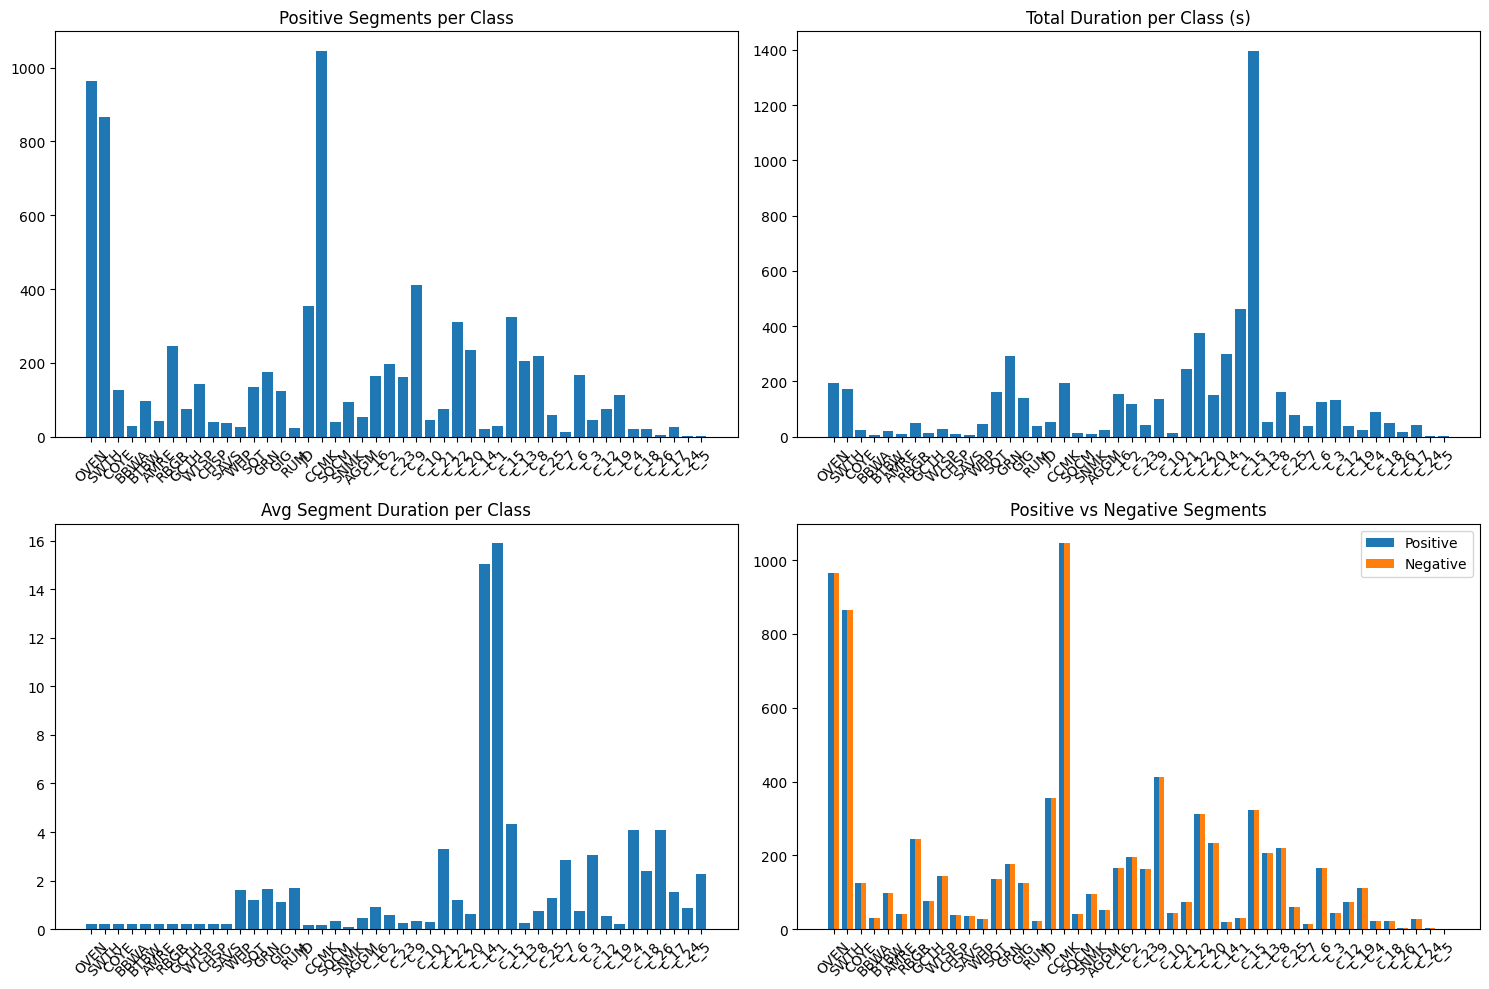

In [24]:
# Balance Visualization

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].bar(df_stats['class'], df_stats['positive_segments'])
axes[0, 0].set_title('Positive Segments per Class')
axes[0, 0].tick_params(axis='x', rotation=45)

axes[0, 1].bar(df_stats['class'], df_stats['total_duration'])
axes[0, 1].set_title('Total Duration per Class (s)')
axes[0, 1].tick_params(axis='x', rotation=45)

axes[1, 0].bar(df_stats['class'], df_stats['avg_duration'])
axes[1, 0].set_title('Avg Segment Duration per Class')
axes[1, 0].tick_params(axis='x', rotation=45)

x = np.arange(len(df_stats))
axes[1, 1].bar(x - 0.2, df_stats['positive_segments'], 0.4, label='Positive')
axes[1, 1].bar(x + 0.2, df_stats['negative_segments'], 0.4, label='Negative')
axes[1, 1].set_title('Positive vs Negative Segments')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(df_stats['class'], rotation=45)
axes[1, 1].legend()

plt.tight_layout()
plt.show()


In [25]:
# Data Quality Checks

print("\n=== Data Quality Checks ===")

low_segment_classes = df_stats[df_stats['positive_segments'] < 5]
if not low_segment_classes.empty:
    print(f"⚠️ Classes with < 5 segments:\n{low_segment_classes[['class', 'positive_segments']]}")

df_stats['neg_pos_ratio'] = df_stats['negative_segments'] / df_stats['positive_segments']
print(f"\nNeg/Pos ratio - Mean: {df_stats['neg_pos_ratio'].mean():.2f}, Std: {df_stats['neg_pos_ratio'].std():.2f}")



=== Data Quality Checks ===
⚠️ Classes with < 5 segments:
   class  positive_segments
42  c_26                  4
44  c_24                  2
45   c_5                  1

Neg/Pos ratio - Mean: 1.00, Std: 0.00



Duration Stats:
Mean: 0.748s, Median: 0.200s
Min: 0.050s, Max: 38.078s


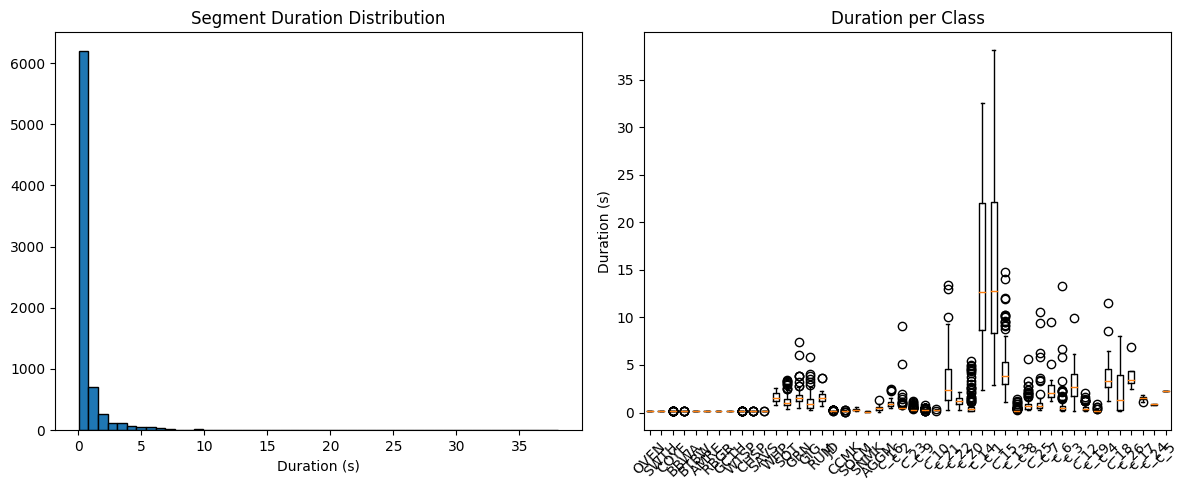

In [26]:
# Duration Distribution

all_durations = [d for cls_data in dataset.meta.values() for d in cls_data['duration']]

print(f"\nDuration Stats:")
print(f"Mean: {np.mean(all_durations):.3f}s, Median: {np.median(all_durations):.3f}s")
print(f"Min: {np.min(all_durations):.3f}s, Max: {np.max(all_durations):.3f}s")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(all_durations, bins=50, edgecolor='black')
plt.xlabel('Duration (s)')
plt.title('Segment Duration Distribution')

plt.subplot(1, 2, 2)
plt.boxplot([dataset.meta[cls]['duration'] for cls in dataset.meta.keys()],
            labels=list(dataset.meta.keys()))
plt.xticks(rotation=45)
plt.ylabel('Duration (s)')
plt.title('Duration per Class')
plt.tight_layout()
plt.show()


In [27]:
# File Distribution

file_usage = {}
for cls_name, cls_data in dataset.meta.items():
    for file_path in cls_data['file']:
        if file_path not in file_usage:
            file_usage[file_path] = {'classes': set(), 'segments': 0}
        file_usage[file_path]['classes'].add(cls_name)
        file_usage[file_path]['segments'] += 1

print(f"Total files: {len(file_usage)}")
print(f"Avg segments per file: {np.mean([f['segments'] for f in file_usage.values()]):.1f}")
print(f"Files with multiple classes: {sum(1 for f in file_usage.values() if len(f['classes']) > 1)}")


Total files: 174
Avg segments per file: 44.1
Files with multiple classes: 17


In [28]:
# Imbalance Detection

cv_segments = df_stats['positive_segments'].std() / df_stats['positive_segments'].mean()
cv_duration = df_stats['total_duration'].std() / df_stats['total_duration'].mean()

print(f"\nImbalance Metrics:")
print(f"Segment count CV: {cv_segments:.3f} {'(High imbalance)' if cv_segments > 0.5 else '(Balanced)'}")
print(f"Duration CV: {cv_duration:.3f} {'(High imbalance)' if cv_duration > 0.5 else '(Balanced)'}")

print(f"\nExtremes:")
print(f"Most segments: {df_stats.loc[df_stats['positive_segments'].idxmax(), 'class']} ({df_stats['positive_segments'].max()})")
print(f"Least segments: {df_stats.loc[df_stats['positive_segments'].idxmin(), 'class']} ({df_stats['positive_segments'].min()})")



Imbalance Metrics:
Segment count CV: 1.407 (High imbalance)
Duration CV: 1.751 (High imbalance)

Extremes:
Most segments: CCMK (1046)
Least segments: c_5 (1)


In [29]:
# Summary Report

cv_segments = df_stats['positive_segments'].std() / df_stats['positive_segments'].mean()
cv_duration = df_stats['total_duration'].std() / df_stats['total_duration'].mean()

print(f"\nImbalance Metrics:")
print(f"Segment count CV: {cv_segments:.3f} {'(High imbalance)' if cv_segments > 0.5 else '(Balanced)'}")
print(f"Duration CV: {cv_duration:.3f} {'(High imbalance)' if cv_duration > 0.5 else '(Balanced)'}")

print(f"\nExtremes:")
print(f"Most segments: {df_stats.loc[df_stats['positive_segments'].idxmax(), 'class']} ({df_stats['positive_segments'].max()})")
print(f"Least segments: {df_stats.loc[df_stats['positive_segments'].idxmin(), 'class']} ({df_stats['positive_segments'].min()})")



Imbalance Metrics:
Segment count CV: 1.407 (High imbalance)
Duration CV: 1.751 (High imbalance)

Extremes:
Most segments: CCMK (1046)
Least segments: c_5 (1)


## Sampling Data

In [ ]:
for each in tqdm(loader):
        x, x_neg, y, y_neg, class_name = each
        print(class_name)
        # import ipdb; ipdb.set_trace()
        # print(torch.mean(x), torch.std(x))
        # print(x.size(), y.size())

TypeError: 'DataLoader' object is not subscriptable